<div align="center">

<!-- Judul Laporan -->
<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h1>
</ul>
<!-- Logo Universitas -->
<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">

<div align="center">

<!-- Penulis -->
<h3>Disusun Oleh:</h3>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>MIFTA AL FADIL</span><span>(H061241048)</span></li>
</ul>
<br><br>
<!-- Departemen dan Fakultas -->
<p><strong>PRODI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>

<!-- Tahun -->
<p><strong>2026</strong></p>

</div>


## **R-GEO-001**
## **Analisis Anomali Geofisika**

### **Deskripsi Proyek**
Proyek ini bertujuan untuk membuat peta anomali geofisika sintetis,
menghitung statistik dasar, serta mengidentifikasi nilai anomali
yang tinggi dan rendah menggunakan Python.

### **Tujuan**
1. Membuat data anomali geofisika sintetis.
2. Memvisualisasikan data dalam bentuk peta.
3. Menghitung statistik dasar data.
4. Mengidentifikasi anomali tinggi dan rendah.
5. Menyimpan hasil analisis.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
from pathlib import Path


# Konfigurasi proyek
PROJECT_NAME = "R-GEO-001: Analisis Anomali Geofisika"

X_MIN = 0
X_MAX = 100
Y_MIN = 0
Y_MAX = 100

GRID_SIZE = 100
NOISE_LEVEL = 1.0
RANDOM_SEED = 42
THRESHOLD_STD = 2.0

OUTPUT_DIR = Path("hasil_R_GEO_001")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Nama proyek:", PROJECT_NAME)
print("Ukuran grid:", GRID_SIZE, "x", GRID_SIZE)
print("Folder hasil:", OUTPUT_DIR)


Nama proyek: R-GEO-001: Analisis Anomali Geofisika
Ukuran grid: 100 x 100
Folder hasil: hasil_R_GEO_001


In [2]:

# Konfigurasi proyek
PROJECT_NAME = "R-GEO-001: Analisis Anomali Geofisika"

X_MIN = 0
X_MAX = 100
Y_MIN = 0
Y_MAX = 100

GRID_SIZE = 100
NOISE_LEVEL = 1.0
RANDOM_SEED = 42
THRESHOLD_STD = 2.0

OUTPUT_DIR = Path("hasil_R_GEO_001")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Nama proyek:", PROJECT_NAME)
print("Ukuran grid:", GRID_SIZE, "x", GRID_SIZE)
print("Folder hasil:", OUTPUT_DIR)


Nama proyek: R-GEO-001: Analisis Anomali Geofisika
Ukuran grid: 100 x 100
Folder hasil: hasil_R_GEO_001


In [5]:

# Membuat grid koordinat
x = np.linspace(X_MIN, X_MAX, GRID_SIZE)
y = np.linspace(Y_MIN, Y_MAX, GRID_SIZE)

X, Y = np.meshgrid(x, y)

# Membuat generator angka acak
rng = np.random.default_rng(RANDOM_SEED)

# Memulai data anomali
anomaly = np.zeros_like(X, dtype=float)

# Sumber anomali sintetis
ANOMALY_SOURCES = [
    (30, 35, 8, 8, 10),
    (70, 65, -10, 12, 9),
    (55, 25, 5, 6, 7),
]

# Membuat pola anomali
for x0, y0, amplitude, sx, sy in ANOMALY_SOURCES:
    anomaly += amplitude * np.exp(
        -(
            ((X - x0) ** 2) / (2 * sx**2)
            + ((Y - y0) ** 2) / (2 * sy**2)
        )
    )

# Menambahkan noise
anomaly += rng.normal(
    0, NOISE_LEVEL, size=anomaly.shape
)

print("Ukuran data:", anomaly.shape)
print("Jumlah titik:", anomaly.size)


Ukuran data: (100, 100)
Jumlah titik: 10000


In [6]:

# Menghitung statistik dasar
nilai_minimum = float(np.min(anomaly))
nilai_maksimum = float(np.max(anomaly))
nilai_rata_rata = float(np.mean(anomaly))
nilai_median = float(np.median(anomaly))
standar_deviasi = float(np.std(anomaly))

print("=== STATISTIK ANOMALI GEOFISIKA ===")
print("Jumlah titik      :", anomaly.size)
print("Nilai minimum     :", round(nilai_minimum, 3))
print("Nilai maksimum    :", round(nilai_maksimum, 3))
print("Nilai rata-rata   :", round(nilai_rata_rata, 3))
print("Nilai median      :", round(nilai_median, 3))
print("Standar deviasi   :", round(standar_deviasi, 3))


=== STATISTIK ANOMALI GEOFISIKA ===
Jumlah titik      : 10000
Nilai minimum     : -11.812
Nilai maksimum    : 10.302
Nilai rata-rata   : -0.148
Nilai median      : -0.018
Standar deviasi   : 2.49


In [7]:

# Menghitung ambang anomali
batas_tinggi = nilai_rata_rata + (
    THRESHOLD_STD * standar_deviasi
)

batas_rendah = nilai_rata_rata - (
    THRESHOLD_STD * standar_deviasi
)

# Mengidentifikasi titik anomali
mask_tinggi = anomaly >= batas_tinggi
mask_rendah = anomaly <= batas_rendah

jumlah_anomali_tinggi = int(np.sum(mask_tinggi))
jumlah_anomali_rendah = int(np.sum(mask_rendah))

print("=== IDENTIFIKASI ANOMALI ===")
print("Ambang tinggi :", round(batas_tinggi, 3))
print("Ambang rendah :", round(batas_rendah, 3))
print("Jumlah titik anomali tinggi :", jumlah_anomali_tinggi)
print("Jumlah titik anomali rendah :", jumlah_anomali_rendah)


=== IDENTIFIKASI ANOMALI ===
Ambang tinggi : 4.831
Ambang rendah : -5.128
Jumlah titik anomali tinggi : 304
Jumlah titik anomali rendah : 450


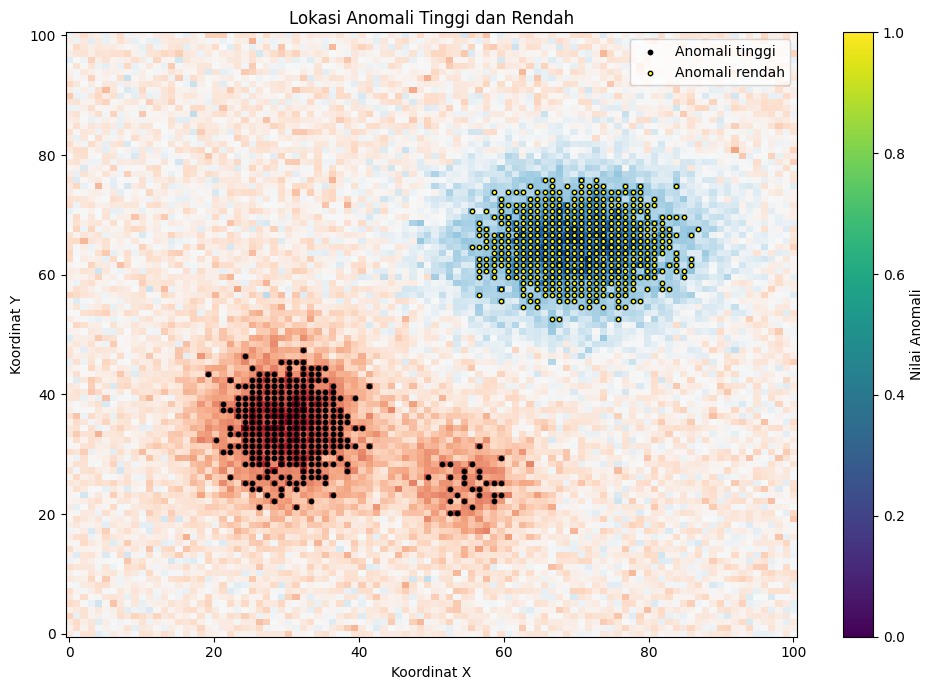

In [8]:

plt.figure(figsize=(10, 7))

plt.pcolormesh(
    X, Y, anomaly,
    shading="auto",
    cmap="RdBu_r"
)

plt.scatter(
    X[mask_tinggi],
    Y[mask_tinggi],
    color="black",
    s=10,
    label="Anomali tinggi"
)

plt.scatter(
    X[mask_rendah],
    Y[mask_rendah],
    color="yellow",
    edgecolors="black",
    s=10,
    label="Anomali rendah"
)

plt.colorbar(label="Nilai Anomali")
plt.xlabel("Koordinat X")
plt.ylabel("Koordinat Y")
plt.title("Lokasi Anomali Tinggi dan Rendah")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "lokasi_anomali_ekstrem.png",
    dpi=300
)

plt.show()


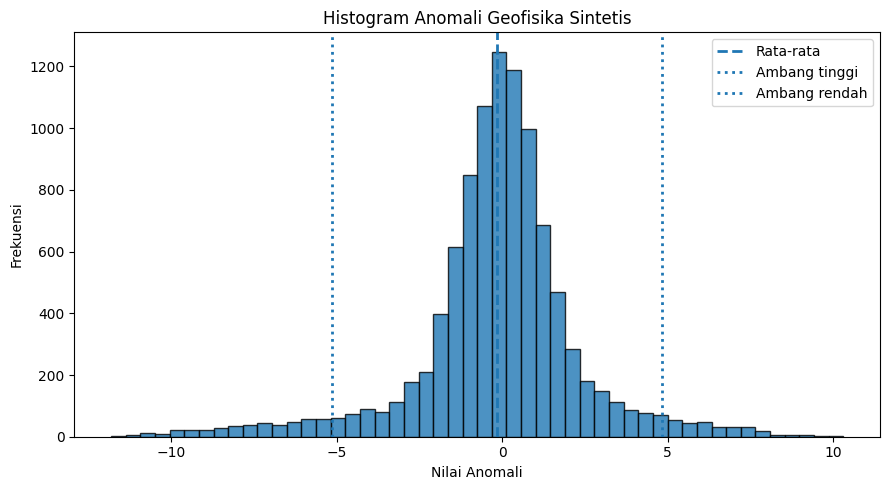

In [9]:

plt.figure(figsize=(9, 5))

plt.hist(
    anomaly.ravel(),
    bins=50,
    edgecolor="black",
    alpha=0.8
)

plt.axvline(
    nilai_rata_rata,
    linestyle="--",
    linewidth=2,
    label="Rata-rata"
)

plt.axvline(
    batas_tinggi,
    linestyle=":",
    linewidth=2,
    label="Ambang tinggi"
)

plt.axvline(
    batas_rendah,
    linestyle=":",
    linewidth=2,
    label="Ambang rendah"
)

plt.title("Histogram Anomali Geofisika Sintetis")
plt.xlabel("Nilai Anomali")
plt.ylabel("Frekuensi")
plt.legend()
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "histogram_anomali.png",
    dpi=300
)

plt.show()


In [10]:

# Mengubah grid menjadi tabel
data_tabel = pd.DataFrame({
    "X": X.ravel(),
    "Y": Y.ravel(),
    "Anomali": anomaly.ravel()
})

# Menambahkan status anomali
data_tabel["Status"] = "Normal"
data_tabel.loc[mask_tinggi.ravel(), "Status"] = "Anomali Tinggi"
data_tabel.loc[mask_rendah.ravel(), "Status"] = "Anomali Rendah"

# Menyimpan tabel ke CSV
file_csv = OUTPUT_DIR / "data_anomali_sintetis.csv"
data_tabel.to_csv(file_csv, index=False)

print("Data berhasil disimpan ke:", file_csv)
display(data_tabel.head(10))


Data berhasil disimpan ke: hasil_R_GEO_001\data_anomali_sintetis.csv


,X,Y,Anomali,Status
0,0.000000,0.0,0.304733,Normal
1,1.010101,0.0,-1.039959,Normal
2,2.020202,0.0,0.750490,Normal
3,3.030303,0.0,0.940624,Normal
4,4.040404,0.0,-1.950945,Normal
5,5.050505,0.0,-1.302044,Normal
6,6.060606,0.0,0.128039,Normal
7,7.070707,0.0,-0.315955,Normal
8,8.080808,0.0,-0.016391,Normal
9,9.090909,0.0,-0.852469,Normal


In [11]:

# Mengumpulkan statistik dalam dictionary
statistik = {
    "nama_proyek": PROJECT_NAME,
    "jenis_data": "Anomali geofisika sintetis",
    "jumlah_titik": int(anomaly.size),
    "minimum": nilai_minimum,
    "maksimum": nilai_maksimum,
    "rata_rata": nilai_rata_rata,
    "median": nilai_median,
    "standar_deviasi": standar_deviasi,
    "ambang_tinggi": float(batas_tinggi),
    "ambang_rendah": float(batas_rendah),
    "jumlah_anomali_tinggi": jumlah_anomali_tinggi,
    "jumlah_anomali_rendah": jumlah_anomali_rendah,
    "catatan": "Data merupakan simulasi, bukan survei lapangan."
}

file_json = OUTPUT_DIR / "statistik_anomali.json"

with open(file_json, "w", encoding="utf-8") as file:
    json.dump(statistik, file, indent=4, ensure_ascii=False)

print("Statistik berhasil disimpan ke:", file_json)


Statistik berhasil disimpan ke: hasil_R_GEO_001\statistik_anomali.json



## **Kesimpulan**

Berdasarkan hasil pelaksanaan proyek **R-GEO-001: Analisis Anomali Geofisika**, dapat disimpulkan bahwa pemrograman Python dapat dimanfaatkan untuk melakukan pembuatan data anomali geofisika sintetis, analisis statistik, visualisasi persebaran anomali, serta identifikasi nilai anomali tinggi dan rendah. Proyek ini dilakukan untuk memahami bagaimana data anomali dapat diolah secara sistematis menggunakan beberapa library Python, seperti NumPy, Pandas, dan Matplotlib.

Pada tahap pembuatan data, digunakan grid koordinat dua dimensi yang terdiri atas 10.000 titik, dengan ukuran 100 × 100. Data anomali dibentuk melalui kombinasi beberapa sumber anomali dengan amplitudo positif dan negatif. Selain itu, ditambahkan gangguan acak (*noise*) untuk memberikan variasi pada data sintetis. Dengan pendekatan tersebut, data yang dihasilkan memiliki pola persebaran nilai yang dapat digunakan sebagai bahan latihan dalam analisis anomali geofisika.

Tahap visualisasi dilakukan dengan membuat peta anomali menggunakan metode pewarnaan berdasarkan nilai data pada setiap koordinat. Peta ini membantu memperlihatkan perbedaan nilai anomali positif dan negatif secara spasial. Warna yang ditampilkan memudahkan pengamatan terhadap lokasi yang memiliki nilai relatif tinggi maupun rendah. Selain peta anomali, histogram dibuat untuk menggambarkan distribusi frekuensi nilai anomali sehingga pola penyebaran data dapat diamati dengan lebih jelas.

Analisis statistik dilakukan dengan menghitung nilai minimum, maksimum, rata-rata, median, dan standar deviasi. Nilai-nilai tersebut memberikan gambaran mengenai rentang, kecenderungan pusat, dan tingkat variasi data. Rata-rata dan median dapat digunakan untuk memahami pusat distribusi nilai, sedangkan standar deviasi menunjukkan seberapa besar penyebaran nilai terhadap rata-ratanya. Hasil statistik ini menjadi dasar untuk melakukan identifikasi nilai anomali yang relatif ekstrem.

Identifikasi anomali tinggi dan rendah dilakukan menggunakan metode ambang batas dua standar deviasi dari nilai rata-rata. Titik dengan nilai yang lebih besar atau sama dengan rata-rata ditambah dua standar deviasi dikategorikan sebagai anomali tinggi. Sebaliknya, titik dengan nilai yang lebih kecil atau sama dengan rata-rata dikurangi dua standar deviasi dikategorikan sebagai anomali rendah. Pendekatan ini membantu mengidentifikasi lokasi yang memiliki nilai berbeda secara signifikan dibandingkan dengan sebagian besar data berdasarkan kriteria yang telah ditentukan. Namun, hasil identifikasi tetap bergantung pada karakteristik distribusi data dan ambang batas yang digunakan.

Seluruh hasil analisis dapat disimpan dalam beberapa format berkas. Peta anomali dan histogram disimpan sebagai gambar PNG, data koordinat beserta nilai anomali disimpan dalam format CSV, sedangkan ringkasan statistik disimpan dalam format JSON. Penyimpanan ini memudahkan proses dokumentasi, pemeriksaan hasil, pengolahan lanjutan, dan penyajian hasil analisis. Dengan demikian, proyek ini tidak hanya menghasilkan visualisasi, tetapi juga menyediakan data dan ringkasan numerik yang dapat digunakan kembali.

Secara keseluruhan, proyek ini memberikan pemahaman dasar mengenai penerapan Python dalam pengolahan dan visualisasi data geofisika. Tahapan yang dilakukan menunjukkan bahwa pembuatan data, perhitungan statistik, pemetaan persebaran nilai, dan identifikasi anomali dapat diintegrasikan ke dalam satu alur kerja yang terstruktur. Kegiatan ini juga menjadi dasar untuk mempelajari metode analisis geofisika yang lebih lanjut, termasuk penggunaan data hasil pengukuran, penerapan metode statistik lainnya, dan pengembangan teknik interpretasi anomali.

Meskipun demikian, terdapat keterbatasan pada proyek ini, yaitu data yang digunakan merupakan **data sintetis hasil simulasi matematika, bukan data pengukuran geofisika dari lapangan**. Oleh karena itu, pola dan nilai yang dihasilkan hanya menggambarkan kondisi simulasi sesuai parameter yang ditentukan. Anomali tinggi atau rendah yang teridentifikasi tidak dapat langsung diartikan sebagai keberadaan struktur geologi atau sumber geofisika tertentu tanpa dukungan data lapangan dan analisis tambahan.

Dengan demikian, proyek **R-GEO-001: Analisis Anomali Geofisika** berhasil menjadi sarana pembelajaran untuk memahami alur dasar analisis anomali menggunakan Python, mulai dari pembuatan data hingga penyimpanan hasil. Pengembangan selanjutnya dapat dilakukan dengan menggunakan data geofisika nyata, membandingkan beberapa metode penentuan ambang anomali, serta menambahkan metode analisis spasial agar hasil yang diperoleh dapat memberikan interpretasi yang lebih mendalam.
